# From SIC measurements to quantum state space

A practical tour of `cirq_sic` 0.2: **construct → inspect → simulate/sample → save → analyze**.

We will reconstruct a qutrit, measure pure- and mixed-state WH entropy, compare
sky/ground experiments, and infer the probability state space from triple products.
Every numerical example is small, reproducible, and executable without a cloud account.

**Setup:** from the repository root run `python -m pip install -e '.[notebooks,test]'`,
then `jupyter lab notebooks/Tutorial.ipynb`. Select the kernel belonging to that environment.
Run cells in order; no previous datasets are needed. Examples use temporary artifact
folders so a rerun never overwrites your research data.

**Read this convention first.** Logical states are the first $d$ computational basis
states of $n=\lceil\log_2 d\rceil$ qubits. Qubit order is big-endian. Cyclic Weyl operators
are $D_{a,b}=X^a Z^b$, and output $k=ad+b$ labels the effect
$E_k=D_{a,b}|\phi\rangle\langle\phi|D_{a,b}^\dagger/d$.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import cirq
from pathlib import Path
import tempfile

from cirq_sic.measurements import Measurement, sic_povm, wh_measurement
from cirq_sic.workflow import (
    Experiment, ExperimentResult, tomography_experiment, entropy_experiment,
    wh_entropy_experiment, sky_ground_experiment, triple_product_experiment,
    compile_circuit,
)
from cirq_sic.analysis import stabilizer_renyi_entropy, born_rule_diagnostics
from cirq_sic.triples import triple_products, triple_product_state_space, sic_state_constraints

rng = np.random.default_rng(2026)
plt.rcParams.update({'figure.figsize': (7, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 11})
print('Cirq', cirq.__version__)

Cirq 1.3.0


## 1. A qutrit SIC on qubit hardware

A qutrit ($d=3$) needs two system qubits. Its nine-outcome SIC needs four measured
qubits in the dense Naimark construction. Output bit strings 9–15 are padding and
have zero ideal probability. They are **retained as leakage** if a noisy device
produces them.

The frame columns $f_k$ obey $\sum_k f_k f_k^\dagger=I$. Therefore
$V_{kj}=\overline{f_{jk}}$ is an isometry. Completing its columns to a unitary gives
an ordinary qubit measurement with the desired probabilities. Input columns must
be placed at $j2^{n_\mathrm{ancilla}}$, because the zero ancillas come *after* the
system. Confusing these columns, or measuring a larger-dimension WH orbit after
padding the fiducial, changes the POVM.

`Measurement` accepts any complete rank-one frame, `wh_measurement` accepts a
normalized fiducial, and `sic_povm` additionally verifies the SIC overlaps.

In [2]:
d = 3
sic = sic_povm(d)
psi = np.array([1, 1j, -0.4 + 0.2j], dtype=complex)
psi /= np.linalg.norm(psi)
experiment = tomography_experiment(psi, sic)
exact = experiment.simulate()
sampled = experiment.run(repetitions=12000, seed=2026)

print(sic)
print('system / measurement ancillas:', sic.num_system_qubits, sic.num_ancilla_qubits)
print('qubit order:', experiment.circuits[0].qubit_order)
print('ideal leakage:', exact['measurement'].leakage)
assert np.allclose(exact['measurement'].valid, sic.probabilities(psi), atol=1e-10)
assert exact['measurement'].leakage < 1e-12
print(experiment.circuits[0].circuit.to_text_diagram())

Measurement(name='SIC-POVM', dimension=3, num_outcomes=9)
system / measurement ancillas: 2 2
qubit order: (cirq.LineQubit(0), cirq.LineQubit(1), cirq.LineQubit(2), cirq.LineQubit(3))
ideal leakage: 0.0
0: ───Prepare[1]───SIC-POVM[1]───M('outcome')───
      │            │             │
1: ───Prepare[2]───SIC-POVM[2]───M──────────────
                   │             │
2: ────────────────SIC-POVM[3]───M──────────────
                   │             │
3: ────────────────SIC-POVM[4]───M──────────────


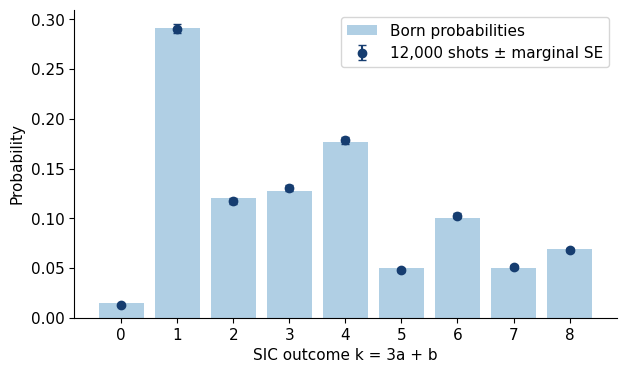

In [3]:
data = sampled['measurement']
x = np.arange(sic.num_outcomes)
fig, ax = plt.subplots()
ax.bar(x, exact['measurement'].valid, alpha=.35, label='Born probabilities')
ax.errorbar(x, data.valid, yerr=data.standard_errors[:sic.num_outcomes],
            fmt='o', color='#163d70', capsize=3, label='12,000 shots ± marginal SE')
ax.set(xlabel='SIC outcome k = 3a + b', ylabel='Probability', xticks=x)
ax.legend()
plt.show()

In [4]:
rho_true = np.outer(psi, psi.conj())
raw = experiment.analyze(sampled)
physical = experiment.analyze(sampled, physical=True)
assert np.allclose(experiment.analyze(exact)['density_matrix'], rho_true, atol=1e-8)
print('Linear-inversion minimum eigenvalue:', raw['minimum_eigenvalue'])
print('Projected minimum eigenvalue:', physical['minimum_eigenvalue'])
print('Reconstruction Frobenius error:', np.linalg.norm(physical['density_matrix'] - rho_true))

Linear-inversion minimum eigenvalue: -0.01493653761732944
Projected minimum eigenvalue: 2.818902889985999e-17
Reconstruction Frobenius error: 0.014916398747555777


The analysis uses observed probabilities, not the state used to build the
preparation circuit. Linear inversion enforces Hermiticity and trace one but may
produce negative eigenvalues with finite shots. `physical=True` projects the
estimate onto the trace-one positive cone in Frobenius norm; it is not maximum
likelihood. The plotted errors are marginal binomial plug-in standard errors,
not simultaneous confidence bands. The outcomes are correlated.

### Save a circuit plan and its data independently

Artifacts are versioned, inspectable JSON containing standard Cirq circuits,
explicit qubit layouts, complex numeric analysis inputs, counts, and execution
metadata. They do not depend on ReCirq or pickle.

In [5]:
artifact_directory = tempfile.TemporaryDirectory(prefix='cirq-sic-tutorial-')
artifact_path = Path(artifact_directory.name)
experiment.save(artifact_path / 'qutrit-plan.json')
sampled.save(artifact_path / 'qutrit-data.json')
restored = Experiment.load(artifact_path / 'qutrit-plan.json')
restored_data = ExperimentResult.load(artifact_path / 'qutrit-data.json')
assert np.array_equal(restored_data['measurement'].counts, sampled['measurement'].counts)
assert np.allclose(restored.analyze(restored_data, physical=True)['density_matrix'],
                   physical['density_matrix'])
print('Saved and reloaded', len(restored.circuits), 'circuit with all counts.')

Saved and reloaded 1 circuit with all counts.


## 2. WH entropy, including mixed states

For a cyclic $d$-dimensional WH operator basis, write
$\chi_{ab}=\mathrm{Tr}(\rho D_{ab})$ and $\gamma=\mathrm{Tr}(\rho^2)$.
The purity-corrected Rényi-2 diagnostic is

$$M_2(\rho)=-\log_2\frac{\sum_{ab}|\chi_{ab}|^4}{d\gamma}.$$

A direct two-copy experiment prepares $\rho\otimes\rho^*$ and measures
$s_{ab}=\mathrm{Tr}(\rho D_{ab}\rho D_{ab}^\dagger)/d$.
Discrete Fourier Parseval gives $\gamma=ds_{00}$ and
$M_2=-\log_2(\sum_{ab}s_{ab}^2/s_{00})$. No tomographic inverse is needed.
The ability to prepare the conjugate state is an assumption: this is not a
universal conjugation channel for an unknown input.

For mixed inputs, preparation uses a unitary purification and unmeasured
environment qubits. They are separate from the measurement ancillas.

In [6]:
qubit_sic = sic_povm(2)
magic = qubit_sic.states[:, 0]
rho_magic = np.outer(magic, magic.conj())
rho_mixed = 0.65 * rho_magic + 0.35 * np.eye(2) / 2
entropy_plan = wh_entropy_experiment(rho_mixed)
entropy_exact = entropy_plan.analyze(entropy_plan.simulate())
entropy_sample = entropy_plan.analyze(entropy_plan.run(repetitions=16000, seed=12))
print('Purity (exact / sampled):', entropy_exact['purity'], entropy_sample['purity'])
print('M2 (exact / sampled):', entropy_exact['entropy'], entropy_sample['entropy'])
assert np.isclose(entropy_exact['entropy'],
                  stabilizer_renyi_entropy(rho_mixed, basis='wh', mixed=True))

Purity (exact / sampled): 0.7112500000000004 0.71625
M2 (exact / sampled): 0.4250422280009031 0.43121339171959205


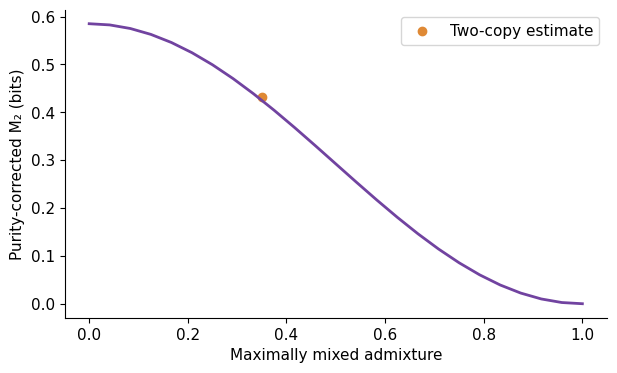

In [7]:
mixing = np.linspace(0, 1, 25)
curve = [stabilizer_renyi_entropy((1-t)*rho_magic + t*np.eye(2)/2,
                                 basis='wh', mixed=True) for t in mixing]
fig, ax = plt.subplots()
ax.plot(mixing, curve, color='#7143a0', lw=2)
ax.scatter([.35], [entropy_sample['entropy']], color='#df8935', label='Two-copy estimate')
ax.set(xlabel='Maximally mixed admixture', ylabel='Purity-corrected M₂ (bits)')
ax.legend()
plt.show()
assert abs(curve[-1]) < 1e-10

The mixed-state extension is a diagnostic, not a faithful magic measure on
the convex hull of stabilizer states. Even $\rho=\mathrm{diag}(0.75,0.25)$ has
positive $M_2$. Finite-shot collision probabilities, ratios, and logarithms are
biased; a small negative estimate is not clipped to zero. If the identity
outcome is never observed, the ratio cannot be estimated and analysis raises.

`basis='pauli'` means tensor-product qubit Paulis. `basis='wh'` means one cyclic
qudit. They agree for a single qubit but differ for $d\ge4$; embedding a qudit in
qubits does not change which operator basis defines your diagnostic.
`entropy_experiment` supplies a complementary route: measure an IC POVM,
reconstruct the state, then evaluate a chosen Rényi order and basis. For sampled
or mixed inputs use `mixed=True` and inspect the reconstruction/projection.

In [8]:
pauli_plan = entropy_experiment(rho_mixed, qubit_sic, basis='pauli', mixed=True)
pauli_report = pauli_plan.analyze(pauli_plan.simulate())
assert np.isclose(pauli_report['entropy'], entropy_exact['entropy'])
print('Tomographic route:', pauli_report['entropy'])

Tomographic route: 0.4250422280009035


## 3. Sky/ground consistency across experiments

For each input state, measure sky probabilities $p_i$ and direct ground
probabilities $q_j$. Independently prepare every normalized reference state
$\sigma_i$ to calibrate $C_{ji}=\mathrm{Tr}(G_j\sigma_i)$ and
$P_{ki}=\mathrm{Tr}(E_k\sigma_i)$. The consistency prediction is

$$q=C P^{-1}p.$$

For an ideal SIC, $P^{-1}=(d+1)I-J/d$, giving the QBist form
$q_j=\sum_i[(d+1)p_i-1/d]C_{ji}$. The experiment measures the reference table
rather than assuming it is ideal. A singular reference is rejected. Ill
conditioning amplifies finite-shot noise and is reported.

Circuits: 14
Reference condition number: 3.012259860896905
Largest absolute residual: 0.025171588340225814


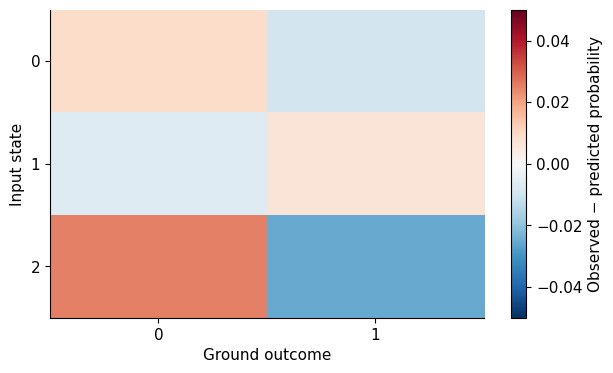

In [9]:
states = [np.array([1., 0.]), np.array([1, 1j])/np.sqrt(2), rho_mixed]
sky_plan = sky_ground_experiment(states, qubit_sic)
sky_exact = sky_plan.analyze(sky_plan.simulate())
sky_sampled = sky_plan.analyze(sky_plan.run(repetitions=10000, seed=35))
assert np.max(np.abs(sky_exact['residual'])) < 1e-9
print('Circuits:', len(sky_plan.circuits))
print('Reference condition number:', sky_sampled['reference_condition'])
print('Largest absolute residual:', np.max(sky_sampled['max_abs_error']))
fig, ax = plt.subplots()
im = ax.imshow(sky_sampled['residual'], cmap='RdBu_r', vmin=-.05, vmax=.05, aspect='auto')
ax.set(xlabel='Ground outcome', ylabel='Input state', xticks=[0, 1], yticks=[0, 1, 2])
fig.colorbar(im, ax=ax, label='Observed − predicted probability')
plt.show()

A consistency residual is a hardware diagnostic, not by itself evidence
against the Born rule. Preparation drift, gate error, leakage and sampling noise
can all matter. An internally consistent noisy device can still satisfy this
relation. To demonstrate sensitivity, the next cell deliberately changes only
the *direct ground* experiments. All other calibration and sky experiments stay
ideal; the mismatch must appear in the residual.

In [10]:
from cirq_sic.workflow import CircuitSpec
changed = []
for spec in sky_plan.circuits:
    circuit = spec.circuit
    if spec.name.startswith('ground/'):
        body = cirq.drop_terminal_measurements(circuit)
        circuit = body + cirq.Circuit(cirq.bit_flip(.12).on(spec.measured_qubits[0]),
                                     cirq.measure(*spec.measured_qubits, key=spec.key))
    changed.append(CircuitSpec(spec.name, circuit, spec.qubit_order, spec.measured_qubits,
                               spec.key, spec.num_outcomes, spec.metadata))
drifting_plan = Experiment(changed, sky_plan.name, sky_plan.metadata, sky_plan.arrays)
drift = drifting_plan.analyze(drifting_plan.simulate())
print('Mismatch with ground-only bit-flip channel:', drift['max_abs_error'])
assert drift['max_abs_error'][0] > .1

Mismatch with ground-only bit-flip channel: [1.20000000e-01 2.22044605e-16 4.50333210e-02]


## 4. Reconstruct probability state space from triple measurements

For SIC projectors $\Pi_i$, measure
$T_{ijk}=\mathrm{Tr}(\Pi_i\Pi_j\Pi_k)$ using a control qubit and a controlled
three-register cycle. Measuring control $X$ yields the real part; control $Y$
yields the imaginary part with a fixed orientation. Both components are tested
in the library, since a reversed cycle conjugates the answer.

Only sorted triples are scheduled by default. Cyclic permutations preserve a
triple and odd permutations conjugate it. Repeated-index imaginary parts vanish.
For $m$ states there are $2\binom{m+2}{3}$ circuits; select a subset in larger
experiments rather than materializing a full $d^6$ tensor.

In [11]:
triple_plan = triple_product_experiment(qubit_sic.states.T)
triple_report = triple_plan.analyze(triple_plan.simulate())
T = triple_report['tensor']
assert np.allclose(T, triple_products(qubit_sic.effects * 2), atol=1e-10)
print('Cycle-test circuits:', len(triple_plan.circuits))
print('An oriented triple:', T[0, 1, 2])
p_magic = qubit_sic.probabilities(magic)
constraints = sic_state_constraints(p_magic, T, 2)
print('Purity / cubic moment:', constraints['purity'], constraints['cubic'])
assert constraints['is_physical'] and constraints['is_pure']

Cycle-test circuits: 40
An oriented triple: -0.1924500897298752j
Purity / cubic moment: 1.0000000000000013 1.000000000000002


The measured tensor supplies a full positivity test, beyond just purity and
cubic moment bounds. Let $G_{jk}=\mathrm{Tr}(\Pi_j\Pi_k)$ and
$A_{i,j,k}=(d+1)T_{j,i,k}-G_{jk}$. A normalized probability vector is physical iff
$\sum_i p_i A_i\succeq0$, for exact SIC triple data. This reconstructs the state
space in probability coordinates without identifying a unique Hilbert-space
orientation. With noisy triples the resulting region is an estimated geometry,
not a certified SIC.

Here is a two-dimensional section through the uniform distribution, using only
the real triple tensor. For a qubit it is a circular section of the Bloch ball
expressed in SIC probability coordinates.

Section output fields: ['A_matrices', 'B', 'active_constraint', 'boundary_x', 'boundary_y', 'x_center']


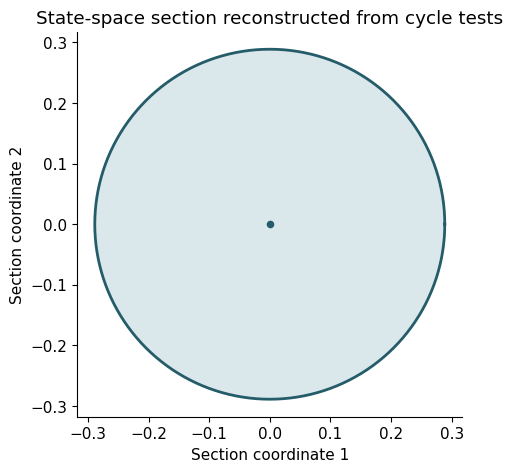

In [12]:
from cirq_sic.geometry import make_sum_zero_section, probability_spectrahedron_section_2D
A = triple_product_state_space(T, 2)
center = np.full(4, .25)
B = make_sum_zero_section([[1, -1, 0, 0], [0, 0, 1, -1]])
section = probability_spectrahedron_section_2D(A, center, B, num_angles=160)
print('Section output fields:', sorted(section))
boundary = section['boundary_y']
closed = np.vstack([boundary, boundary[0]])
fig, ax = plt.subplots(figsize=(5, 5))
ax.fill(closed[:, 0], closed[:, 1], color='#4c8f9b', alpha=.2)
ax.plot(closed[:, 0], closed[:, 1], color='#245c69', lw=2)
ax.scatter([0], [0], color='#245c69', s=20)
ax.set(xlabel='Section coordinate 1', ylabel='Section coordinate 2',
       title='State-space section reconstructed from cycle tests', aspect='equal')
plt.show()
assert np.all(section['boundary_x'] >= -1e-10)


## 5. Compile, inspect, and iterate

The mathematical construction contains dense unitary gates. `compile_circuit`
synthesizes one- and two-qubit operations and targets CZ gates by default. The
synthesis uses a stable Schur-based decomposition for degenerate padded blocks.
This is a correctness reference, not a low-depth SIC synthesis algorithm.
A SIC dilation stores $O(d^4)$ complex numbers and dense completion costs roughly
$O(d^6)$; hardware gate counts grow quickly. Arbitrary dimension means the
encoding has no power-of-two restriction, not that every dimension is affordable.

Gate synthesis does not route or validate against a particular device topology.
After your own placement/routing, supply a `cirq.Sampler` to `plan.run(...)`.
If routing changes qubits, construct updated `CircuitSpec` layouts explicitly.
Do not reuse the old output order. No cloud submission is performed here.

In [13]:
compiled = experiment.transform(compile_circuit)
ops = list(compiled.circuits[0].circuit.all_operations())
print('Qutrit synthesis operations:', len(ops))
print('Two-qubit gates:', sum(len(op.qubits) == 2 and not cirq.is_measurement(op) for op in ops))
assert all(len(op.qubits) <= 2 or cirq.is_measurement(op) for op in ops)
assert np.allclose(compiled.simulate()['measurement'].probabilities,
                   exact['measurement'].probabilities, atol=1e-7)
# Same execution API with an explicitly supplied local sampler:
backend_result = compiled.run(cirq.Simulator(seed=20), repetitions=1000)
print('Total sampled shots:', backend_result['measurement'].counts.sum())

Qutrit synthesis operations: 374
Two-qubit gates: 122
Total sampled shots: 1000


## Where to go next

- [EmbeddingTest.ipynb](EmbeddingTest.ipynb): dimension sweep, padding and outcome conventions.
- [TestingMixedSE.ipynb](TestingMixedSE.ipynb): mixed WH entropy and its interpretation.
- [TaskExample.ipynb](TaskExample.ipynb): experiment artifacts and sky/ground batteries.
- [TripleProducts.ipynb](TripleProducts.ipynb): measured tensor and positivity reconstruction.
- [API guide](../docs/api.md), [mathematical conventions](../docs/mathematics.md), and [migration guide](../docs/migration.md).

Run `python -m pytest` for the regression suite. Run
`python tools/execute_notebooks.py` to execute every maintained notebook in a
fresh kernel; pass `--write` to refresh saved outputs after edits.

Primary references: [Leone, Oliviero & Hamma, stabilizer Rényi entropy](https://arxiv.org/abs/2106.12587),
[Appleby, Ericsson & Fuchs, QBist state spaces](https://arxiv.org/abs/0910.2750),
[Shende, Bullock & Markov, quantum circuit synthesis](https://arxiv.org/abs/quant-ph/0406176),
and the [Cirq documentation](https://quantumai.google/cirq).